# Deepfake Detection using Xception

This project trains a model on a large dataset to detect AI-generated images. We then check how well it works on our own images and improve it.

## 1. Setup and data download

We install the libraries, connect Google Drive, and download the CIFAKE dataset of real and AI-generated images.

In [1]:
!pip install -q opencv-python-headless kagglehub

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras import layers, models

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json, os

# Set KAGGLE_USERNAME and KAGGLE_KEY as Colab secrets / environment variables.
# Never commit real credentials.
os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump({'username': os.environ['KAGGLE_USERNAME'], 'key': os.environ['KAGGLE_KEY']}, f)
os.chmod('/root/.kaggle/kaggle.json', 0o600)


In [4]:
import glob

zip_dir = '/content/drive/MyDrive/deepfake_project/cifake_zip'
os.makedirs(zip_dir, exist_ok=True)

if not os.path.exists('/content/data/train'):
    zips = glob.glob(f'{zip_dir}/*.zip')
    if not zips:
        !kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images -p {zip_dir}
        zips = glob.glob(f'{zip_dir}/*.zip')
    !unzip -q "{zips[0]}" -d /content/data
print("Data ready:", os.path.exists('/content/data/train'))

Data ready: True


In [5]:
import os
for root, dirs, files_ in os.walk('/content/data'):
    print(root, len(files_), 'files')

/content/data 0 files
/content/data/test 0 files
/content/data/test/REAL 10000 files
/content/data/test/FAKE 10000 files
/content/data/train 0 files
/content/data/train/REAL 50000 files
/content/data/train/FAKE 50000 files


## 2. Data exploration and loading

We look at sample images and prepare the data so the model can read it in batches.

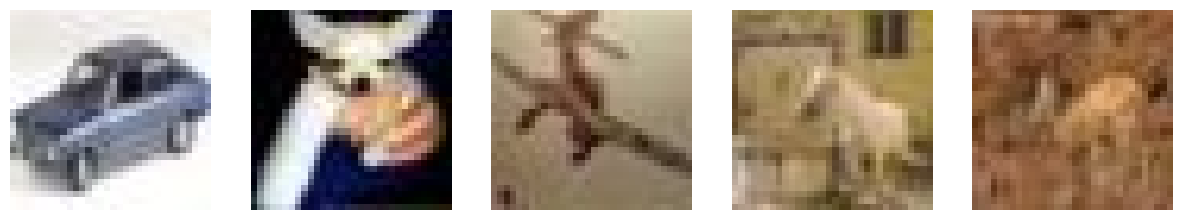

In [6]:
import matplotlib.pyplot as plt
import cv2

sample_path = '/content/data/train/REAL'
sample_files = os.listdir(sample_path)[:5]

fig, axes = plt.subplots(1, 5, figsize=(15,3))
for ax, fname in zip(axes, sample_files):
    img = cv2.imread(os.path.join(sample_path, fname))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.show()

In [7]:
import glob, random

IMG_SIZE = 299
BATCH_SIZE = 32

# Training images and labels (FAKE = 0, REAL = 1)
fake_paths = glob.glob('/content/data/train/FAKE/*')
real_paths = glob.glob('/content/data/train/REAL/*')
paths = fake_paths + real_paths
labels = [0] * len(fake_paths) + [1] * len(real_paths)

combined = list(zip(paths, labels))
random.seed(42)
random.shuffle(combined)
paths, labels = zip(*combined)

def make_dataset(path_list, label_list, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((list(path_list), list(label_list)))
    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        img = tf.keras.applications.xception.preprocess_input(img)
        return img, tf.cast(label, tf.float32)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(2000)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Test images, shuffled so real and fake are mixed
test_fake = glob.glob('/content/data/test/FAKE/*')
test_real = glob.glob('/content/data/test/REAL/*')
tmp = list(zip(test_fake + test_real, [0]*len(test_fake) + [1]*len(test_real)))
random.seed(7)
random.shuffle(tmp)
test_paths, test_labels = zip(*tmp)

test_ds = make_dataset(test_paths, test_labels)
val_small_ds = make_dataset(test_paths[:4000], test_labels[:4000])
print("Total training images:", len(paths))

Total training images: 100000


## 3. Model and staged training (Xception transfer learning)

We take Xception, which is already trained on ImageNet, and fine-tune it in five stages using more images each time.

In [8]:
base_model = tf.keras.applications.Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(299, 299, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,863,529 (79.59 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

In [9]:
import re

save_dir = '/content/drive/MyDrive/deepfake_project/models'
os.makedirs(save_dir, exist_ok=True)
results_file = '/content/drive/MyDrive/deepfake_project/stage_results.csv'

stages = [
    {"records": 20000,  "epochs": 4},
    {"records": 40000,  "epochs": 4},
    {"records": 60000,  "epochs": 6},
    {"records": 80000,  "epochs": 6},
    {"records": 100000, "epochs": 8},
]

saved_files = {}
for f in glob.glob(f'{save_dir}/xception_stage*_*.h5'):
    saved_files[int(re.search(r'stage(\d+)_', f).group(1))] = f
done = max(saved_files, default=0)

if done > 0:
    print(f"Loading model from stage {done}, continuing from stage {done+1}")
    model = tf.keras.models.load_model(saved_files[done])
else:
    base_model.trainable = True
    for layer in base_model.layers[:-20]:
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='binary_crossentropy', metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=2, restore_best_weights=True)

for i, stage in enumerate(stages, start=1):
    if i <= done:
        continue
    n = stage["records"]
    print(f"\n===== STAGE {i}: {n} images, up to {stage['epochs']} epochs =====")

    train_stage_ds = make_dataset(paths[:n], labels[:n], shuffle=True)
    history = model.fit(train_stage_ds, validation_data=val_small_ds,
                        epochs=stage["epochs"], callbacks=[early_stop])

    model.save(f'{save_dir}/xception_stage{i}_{n}.h5')
    print(f"Saved model after stage {i}")

    row = {"stage": i, "records": n, "max_epochs": stage["epochs"],
           "epochs_run": len(history.history['accuracy']),
           "train_acc": history.history['accuracy'][-1],
           "val_acc": history.history['val_accuracy'][-1]}
    pd.DataFrame([row]).to_csv(results_file, mode='a',
                               header=not os.path.exists(results_file), index=False)

Loading model from stage 5, continuing from stage 6


In [10]:
import pandas as pd
results_df = pd.read_csv('/content/drive/MyDrive/deepfake_project/stage_results.csv')
print(results_df)

   stage  records  max_epochs  epochs_run  train_acc  val_acc
0      1    20000           4           4   0.935600  0.94075
1      2    40000           4           4   0.969400  0.96250
2      3    60000           6           6   0.987883  0.96850
3      4    80000           6           4   0.989175  0.97300
4      5   100000           8           5   0.993140  0.97425


## 4. CIFAKE Evaluation

We test the model on unseen CIFAKE images and it scores 97.53% accuracy.

In [11]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")

625/625 ━━━━━━━━━━━━━━━━━━━━ 173s 254ms/step - accuracy: 0.9753 - loss: 0.0720
Final Test Accuracy: 97.53%


## 5. Testing on custom images
The CIFAKE-trained model is evaluated on the custom real/fake images and fails (predicts 'fake' for everything).

We test the model on our own photos, and it fails by calling every image fake.

In [13]:
from PIL import Image, ImageOps
import os
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

base = '/content/drive/MyDrive/deepfake_project/models/custom_data'
out = '/content/drive/MyDrive/deepfake_project/models/custom_data_clean'

for label in ['real', 'fake']:
    src = f'{base}/{label}'
    dst = f'{out}/{label}'
    os.makedirs(dst, exist_ok=True)

    files = sorted(f for f in os.listdir(src)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))
    saved = 0
    for f in files:
        try:
            img = Image.open(os.path.join(src, f))
            img = ImageOps.exif_transpose(img)
            img = img.convert('RGB')
            img = ImageOps.fit(img, (299, 299), method=Image.LANCZOS)
            saved += 1
            img.save(f'{dst}/{label}_{saved:03d}.jpg', 'JPEG', quality=90)
        except Exception as e:
            print("Skipped:", f, "->", e)
    print(f"{label}: {saved} images saved (from {len(files)} files)")

real: 85 images saved (from 85 files)
fake: 75 images saved (from 75 files)


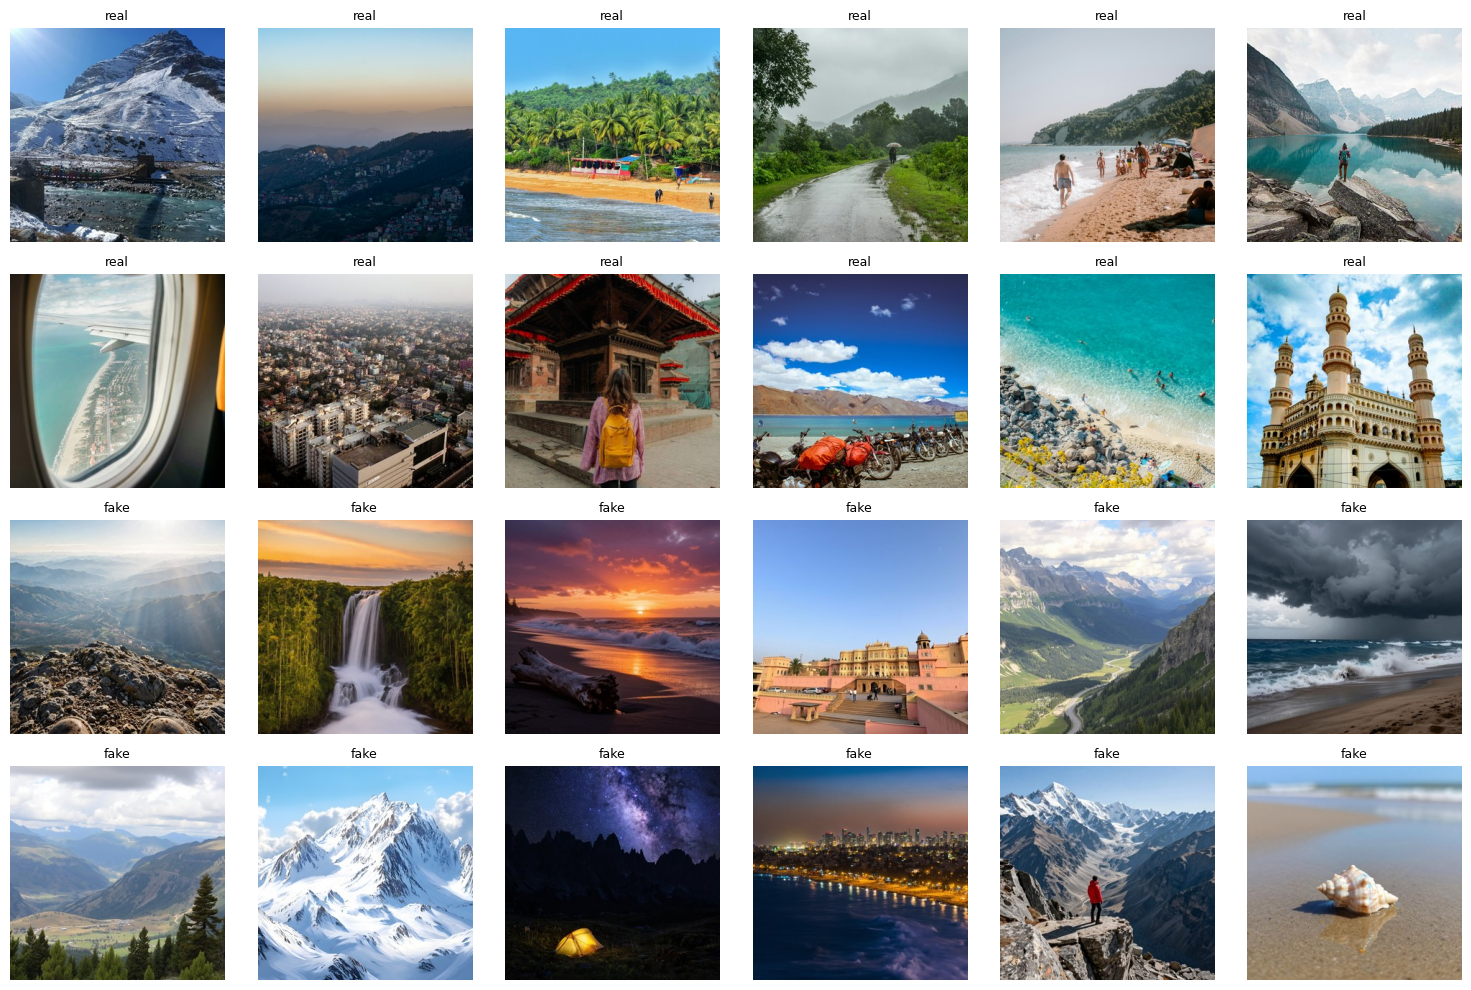

In [14]:
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for r, label in enumerate(['real', 'fake']):
    folder = f'{out}/{label}'
    names = random.sample(sorted(os.listdir(folder)), min(12, len(os.listdir(folder))))
    for i, name in enumerate(names):
        ax = axes[r * 2 + i // 6][i % 6]
        ax.imshow(Image.open(os.path.join(folder, name)))
        ax.set_title(label, fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report

if 'model' not in globals():
    model = tf.keras.models.load_model(
        '/content/drive/MyDrive/deepfake_project/models/xception_stage5_100000.h5')

custom_ds = tf.keras.utils.image_dataset_from_directory(
    out, class_names=['fake', 'real'],               # fake = 0, real = 1
    image_size=(299, 299), batch_size=16, shuffle=False)
file_names = custom_ds.file_paths

custom_ds = custom_ds.map(
    lambda x, y: (tf.keras.applications.xception.preprocess_input(x), y))

y_true = np.concatenate([y.numpy() for _, y in custom_ds])
probs = model.predict(custom_ds).ravel()
y_pred = (probs > 0.5).astype(int)

print("Accuracy:", round((y_pred == y_true).mean() * 100, 2), "%")
print("\nConfusion matrix (rows = actual, columns = predicted; order: fake, real)")
print(confusion_matrix(y_true, y_pred))
print("\n", classification_report(y_true, y_pred, target_names=['fake', 'real']))

wrong = [(os.path.basename(p), round(float(pr), 2)) for p, pr, t, y in
         zip(file_names, probs, y_true, y_pred) if t != y]
print(f"\nWrong predictions: {len(wrong)}")
print(wrong[:20])

Found 160 files belonging to 2 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 143ms/step
Accuracy: 46.88 %

Confusion matrix (rows = actual, columns = predicted; order: fake, real)
[[75  0]
 [85  0]]

               precision    recall  f1-score   support

        fake       0.47      1.00      0.64        75
        real       0.00      0.00      0.00        85

    accuracy                           0.47       160
   macro avg       0.23      0.50      0.32       160
weighted avg       0.22      0.47      0.30       160


Wrong predictions: 85
[('real_001.jpg', 0.0), ('real_002.jpg', 0.0), ('real_003.jpg', 0.0), ('real_004.jpg', 0.0), ('real_005.jpg', 0.0), ('real_006.jpg', 0.0), ('real_007.jpg', 0.0), ('real_008.jpg', 0.0), ('real_009.jpg', 0.0), ('real_010.jpg', 0.0), ('real_011.jpg', 0.0), ('real_012.jpg', 0.0), ('real_013.jpg', 0.0), ('real_014.jpg', 0.0), ('real_015.jpg', 0.0), ('real_016.jpg', 0.0), ('real_017.jpg', 0.0), ('real_018.jpg', 0.0), ('real_019.jpg', 0.0), ('real_020.jpg', 0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## 6. Diagnosis

We find out why it fails: the model learned CIFAKE-specific patterns and has no useful signal on our images (AUC of about 0.49).

In [16]:
def cifake_style(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (32, 32), method='area')
    img = tf.image.resize(img, (299, 299))
    return tf.keras.applications.xception.preprocess_input(img), label

import glob
paths_c = sorted(glob.glob(f'{out}/fake/*.jpg')) + sorted(glob.glob(f'{out}/real/*.jpg'))
labels_c = [0]*len(glob.glob(f'{out}/fake/*.jpg')) + [1]*len(glob.glob(f'{out}/real/*.jpg'))

ds32 = tf.data.Dataset.from_tensor_slices((paths_c, labels_c)).map(cifake_style).batch(16)
probs32 = model.predict(ds32).ravel()
print("Accuracy with CIFAKE-style preprocessing:", ((probs32 > 0.5) == np.array(labels_c)).mean())

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step
Accuracy with CIFAKE-style preprocessing: 0.4875


In [17]:
from sklearn.metrics import roc_auc_score, roc_curve
print("AUC:", roc_auc_score(labels_c, probs32))

fpr, tpr, thr = roc_curve(labels_c, probs32)
best = thr[np.argmax(tpr - fpr)]
print("Best threshold:", best)
print("Accuracy at best threshold:", ((probs32 > best) == np.array(labels_c)).mean())

AUC: 0.44329411764705884
Best threshold: 0.85633475
Accuracy at best threshold: 0.5


## 7. Improved accuracy on our custom images

We use pre-trained Xception features with a simple classifier trained on our own images, and measure it with cross-validation. This reaches about 73%, compared with about 50% for the original model.

In [18]:
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

fake_files = sorted(glob.glob(f'{out}/fake/*.jpg'))
real_files = sorted(glob.glob(f'{out}/real/*.jpg'))
image_paths = fake_files + real_files
y = np.array([0] * len(fake_files) + [1] * len(real_files))


xception = tf.keras.applications.Xception(weights='imagenet', include_top=False,
                                          pooling='avg', input_shape=(299, 299, 3))
mid_layer = tf.keras.layers.GlobalAveragePooling2D()(
    xception.get_layer('block7_sepconv3_act').output)
extractor = tf.keras.Model(xception.input, [xception.output, mid_layer])

def load_image(path):
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (299, 299))
    return tf.keras.applications.xception.preprocess_input(img)

ds = tf.data.Dataset.from_tensor_slices(image_paths).map(load_image).batch(16)
final_feats, mid_feats = extractor.predict(ds)
X = np.hstack([final_feats, mid_feats])

clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

acc = cross_val_score(clf, X, y, cv=cv, scoring='accuracy')
auc = cross_val_score(clf, X, y, cv=cv, scoring='roc_auc')

print(f"Images used: {len(y)} ({len(fake_files)} fake, {len(real_files)} real)")
print(f"Cross-validated accuracy: {acc.mean()*100:.1f}%")
print(f"Cross-validated AUC:      {auc.mean():.3f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step
Images used: 160 (75 fake, 85 real)
Cross-validated accuracy: 74.0%
Cross-validated AUC:      0.793


## Why the accuracy is low

Domain shift -- CIFAKE has tiny, low-quality 32×32 pictures, which are enlarged to 299×299 and become blurry. Custom images are sharp, high-resolution photos. The model only knows what it was trained on, so it doesn’t work well on images that look different.

All the fake images in CIFAKE come from one AI generator, which leaves its own small traces in the pixels. The model learned to spot those traces and not whether a scene is realistic. Custom photos don’t have those traces, so the model has nothing to go on. That is why it called every image fake.

Small custom set. We only have about 50 images per class, so the result is noisy.